<a href="https://colab.research.google.com/github/gaduridigital/AI-Trip-Planner/blob/main/Example_Stress_Strain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# =====================================================
# STRESS-STRAIN DATA ANALYSIS USING PYTHON
# Platform: Google Colab
# Library: Pandas
# =====================================================

# STEP 1: Import Libraries

import pandas as pd
from google.colab import files


# STEP 2: Upload CSV File

uploaded = files.upload()

df = pd.read_csv("stress_strain_practice.csv")


# STEP 3: Display First 5 Rows

print("\n--- First 5 Rows ---")
print(df.head())


# STEP 4: Check Dataset Information

print("\n--- Dataset Information ---")
print(df.info())

print("\n--- Missing Values ---")
print(df.isnull().sum())


# STEP 5: Clean Data

required_columns = [
    "Test_ID",
    "Material",
    "Force_N",
    "Cross_Section_Area_mm2",
    "Elongation_mm",
    "Original_Length_mm",
    "Test_Date"
]

df = df.dropna(subset=required_columns)

df = df[
    (df["Cross_Section_Area_mm2"] > 0) &
    (df["Original_Length_mm"] > 0)
].copy()


# STEP 6: Calculate Stress (MPa)

# Stress = Force / Cross-sectional Area

df["Stress_MPa"] = (
    df["Force_N"] / df["Cross_Section_Area_mm2"]
)


# STEP 7: Calculate Strain (%)

# Strain = (Elongation / Original Length) * 100

df["Strain_Percent"] = (
    df["Elongation_mm"] /
    df["Original_Length_mm"]
) * 100


# STEP 8: Display Calculated Results

print("\n--- Stress and Strain Results ---")

print(
    df[
        ["Test_ID", "Material", "Stress_MPa", "Strain_Percent"]
    ].round(2)
)


# STEP 9: Group Results by Material

material_analysis = df.groupby("Material").agg(
    Average_Stress_MPa=("Stress_MPa", "mean"),
    Average_Strain_Percent=("Strain_Percent", "mean")
).reset_index()

print("\n--- Material-wise Average Analysis ---")

print(material_analysis.round(2))


# STEP 10: Identify Strongest Material

strongest_material = material_analysis.loc[
    material_analysis["Average_Stress_MPa"].idxmax()
]

print("\n--- Strongest Material ---")

print("Material:", strongest_material["Material"])

print(
    "Average Stress:",
    round(strongest_material["Average_Stress_MPa"], 2),
    "MPa"
)


# STEP 11: Calculate Min, Max and Average Stress

stress_summary = df.groupby("Material").agg(
    Minimum_Stress_MPa=("Stress_MPa", "min"),
    Maximum_Stress_MPa=("Stress_MPa", "max"),
    Average_Stress_MPa=("Stress_MPa", "mean")
).reset_index()

print("\n--- Stress Summary ---")

print(stress_summary.round(2))


# STEP 12: Export Results to CSV

df.to_csv("stress_strain_results.csv", index=False)

material_analysis.round(2).to_csv(
    "material_analysis.csv",
    index=False
)

stress_summary.round(2).to_csv(
    "stress_summary.csv",
    index=False
)


# STEP 13: Download CSV Files

files.download("stress_strain_results.csv")

files.download("material_analysis.csv")

files.download("stress_summary.csv")


print("\nStress-Strain Analysis Completed Successfully!")

Saving stress_strain_practice.csv to stress_strain_practice (1).csv

--- First 5 Rows ---
  Test_ID  Material  Force_N  Cross_Section_Area_mm2  Elongation_mm  \
0    T001     Steel     1749                      27           0.51   
1    T002  Aluminum     2901                      20           0.45   
2    T003    Copper     2463                      19           0.76   
3    T004     Brass     2197                      33           0.50   
4    T005  Titanium     1312                      33           0.45   

   Original_Length_mm   Test_Date  
0                 100  2025-01-01  
1                 100  2025-01-02  
2                 100  2025-01-03  
3                 100  2025-01-04  
4                 100  2025-01-05  

--- Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Test_ID                 3

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Stress-Strain Analysis Completed Successfully!


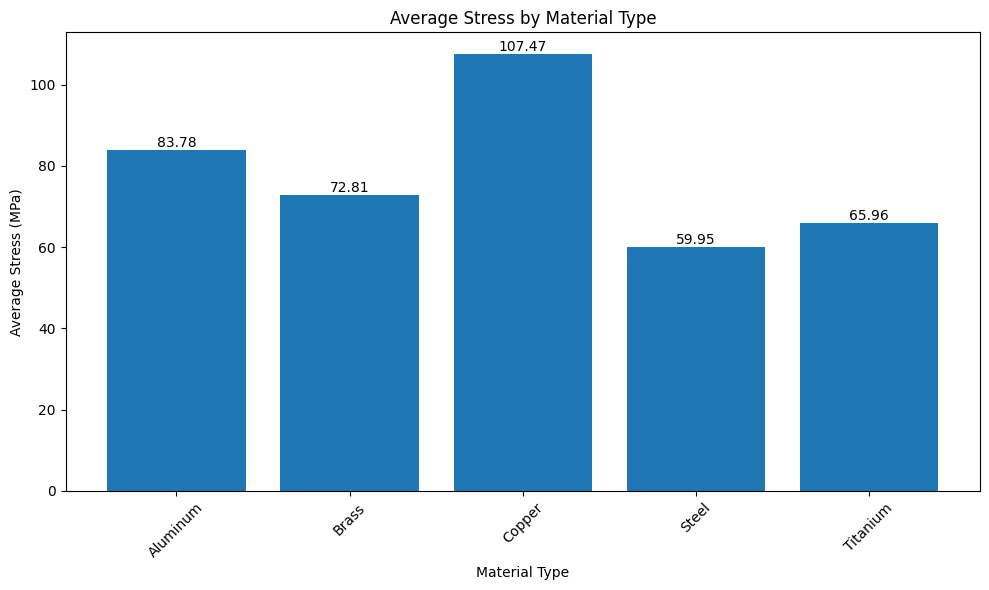

In [2]:
# STEP 9: VISUALIZE STRESS VS MATERIAL TYPE

import matplotlib.pyplot as plt

# Calculate average stress for each material
average_stress = df.groupby("Material")["Stress_MPa"].mean()

# Create bar chart
plt.figure(figsize=(10, 6))

plt.bar(
    average_stress.index,
    average_stress.values
)

# Add chart title and labels
plt.title("Average Stress by Material Type")

plt.xlabel("Material Type")

plt.ylabel("Average Stress (MPa)")

# Display values above each bar
for index, value in enumerate(average_stress.values):
    plt.text(index, value, f"{value:.2f}", ha="center", va="bottom")

# Improve chart appearance
plt.xticks(rotation=45)

plt.tight_layout()

# Display chart
plt.show()

In [3]:
# STEP: IDENTIFY TESTS WHERE STRESS EXCEEDS 200 MPa

# Filter tests with stress greater than 200 MPa
high_stress_tests = df[df["Stress_MPa"] > 200].copy()

print("\n--- Tests Exceeding 200 MPa ---")

if not high_stress_tests.empty:

    print(high_stress_tests[
        ["Test_ID", "Material", "Stress_MPa"]
    ])

    print("\nTotal High-Stress Tests:", len(high_stress_tests))

else:
    print("No tests exceeded 200 MPa.")


# Highlight high-stress tests in the dataset
df["Stress_Status"] = df["Stress_MPa"].apply(
    lambda stress: "HIGH STRESS" if stress > 200 else "NORMAL"
)


# Export high-stress tests separately
high_stress_tests.to_csv(
    "high_stress_tests.csv",
    index=False
)

# Download the report
from google.colab import files

files.download("high_stress_tests.csv")


--- Tests Exceeding 200 MPa ---
No tests exceeded 200 MPa.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# STEP: ERROR HANDLING FOR MISSING VALUES

# 1. Check missing values in each column

print("\n--- Missing Values Before Cleaning ---")

print(df.isnull().sum())


# 2. Handle missing values

# Remove rows where essential columns are missing

required_columns = [
    "Test_ID",
    "Material",
    "Force_N",
    "Cross_Section_Area_mm2",
    "Elongation_mm",
    "Original_Length_mm",
    "Test_Date"
]

# Count missing rows before cleaning
initial_rows = len(df)

# Remove rows containing missing values
df = df.dropna(subset=required_columns).copy()

removed_rows = initial_rows - len(df)

print("\nRows removed due to missing values:", removed_rows)


# 3. Check for invalid numerical values

df = df[
    (df["Cross_Section_Area_mm2"] > 0) &
    (df["Original_Length_mm"] > 0)
].copy()


# 4. Final missing value verification

print("\n--- Missing Values After Cleaning ---")

print(df.isnull().sum())


# 5. Display cleaned dataset

print("\n--- Cleaned Dataset ---")

print(df.head())


# 6. Check whether dataset is empty

if df.empty:
    raise ValueError(
        "Error: No valid records available after data cleaning!"
    )

print("\nData cleaning completed successfully!")


--- Missing Values Before Cleaning ---
Test_ID                   0
Material                  0
Force_N                   0
Cross_Section_Area_mm2    0
Elongation_mm             0
Original_Length_mm        0
Test_Date                 0
Stress_MPa                0
Strain_Percent            0
Stress_Status             0
dtype: int64

Rows removed due to missing values: 0

--- Missing Values After Cleaning ---
Test_ID                   0
Material                  0
Force_N                   0
Cross_Section_Area_mm2    0
Elongation_mm             0
Original_Length_mm        0
Test_Date                 0
Stress_MPa                0
Strain_Percent            0
Stress_Status             0
dtype: int64

--- Cleaned Dataset ---
  Test_ID  Material  Force_N  Cross_Section_Area_mm2  Elongation_mm  \
0    T001     Steel     1749                      27           0.51   
1    T002  Aluminum     2901                      20           0.45   
2    T003    Copper     2463                      19      